In [1]:
import pandas as pd
import numpy as np
import scipy.stats as stats
import statsmodels.api as sm
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

In [2]:
# import matplotlib as mpl
# mpl.rcParams.update({
#     "pgf.texsystem": "pdflatex",
#     'font.family': 'serif',
#     'font.serif' : "Computer Modern",
#     'text.usetex': True,
#     'pgf.rcfonts': False,
# })
# mpl.use('pgf')

In [3]:
# Reading Log Returns for Each Asset and the Interest Rates for the Credit

# STOCK DATA
portfolio_df = pd.read_csv("_portfolio_returns.csv", index_col=["Date"], parse_dates = True).drop(columns=["EUR_USD"])
loss_df = -portfolio_df
# loss_df = loss_df.drop(columns=["EUR_USD"]) # For now just drop, need answer to Q1
# loss_df = loss_df*(-1)      # Converting into Loss Distribution. instead of P/L, IT IS THAT SIMPLE RIGHT?

# Reading Rates for Credit
euribor = pd.read_csv("_EURIBOR_monthly_rates.csv", index_col=["Date"], parse_dates=True).resample('1d').last().ffill()
# ...       # Nothing for now, need answer to Q2
loan_position = (1 - (euribor / 100)) ** (1 / 365) - 1

loss_df = loss_df.loc[loan_position.index]
portfolio_df = portfolio_df.loc[loan_position.index]
# Declaring weights for portfolio construction, DON'T FORGET TO UPDAtE ONCE CREDIT IS ADDED
PORTFOLIO_WEIGHTS= np.array([0.075, 0.1, 0.075, 0.075, 0.075, 0.1, 0.5])    # If we short something we can get more cash to invest

In [4]:
loss_df['loan'] = -loan_position
portfolio_df['loan'] = loan_position

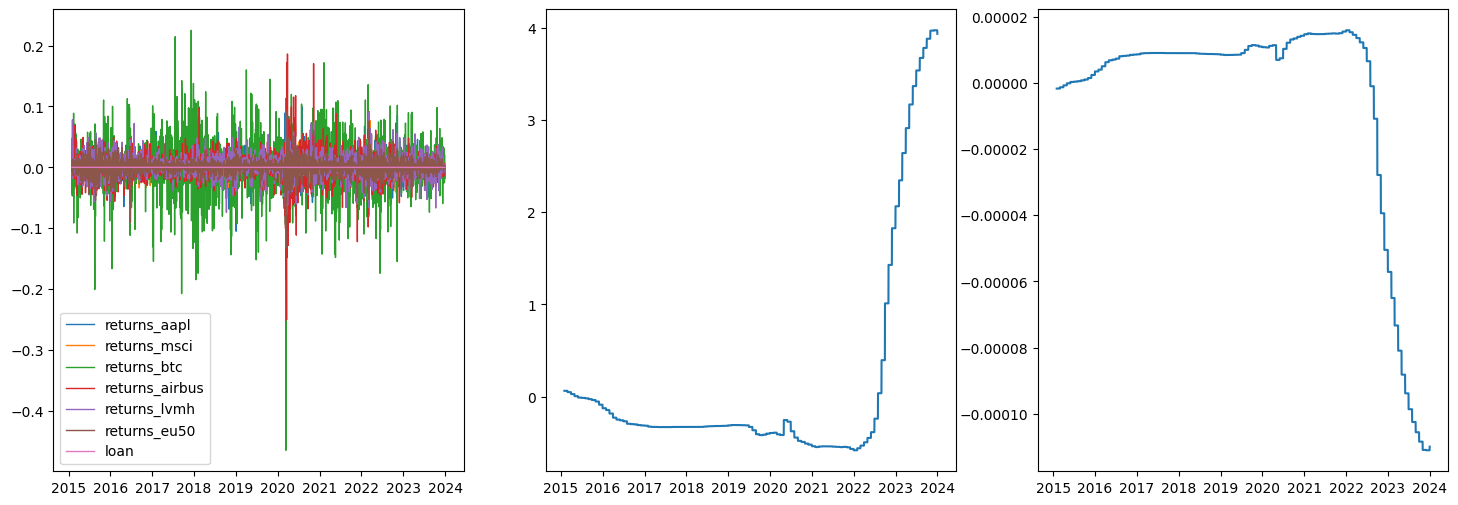

In [5]:
fig, axs = plt.subplots(1,3, figsize = (18, 6))
axs[0].plot(portfolio_df, label = portfolio_df.columns, lw = 1)
axs[1].plot(euribor)
axs[2].plot(portfolio_df.loan)
axs[0].legend()
plt.show()

In [6]:
from typing import Callable, Any

def LossDist(_) -> Any : return -_

def PortRet(*, data: pd.DataFrame, weights: np.array) -> pd.DataFrame:

    assert np.sum(weights) == 1
    return data @ weights

In [7]:
def Var_Cov_VaR(data: pd.DataFrame, window_size: int, port_weights: np.array, alpha: float, dist: Callable, **kwargs) -> float | pd.DataFrame:
    """
    Calculate the Value at Risk metric using dist
    """

    pf_vol = [np.nan] * window_size
    for k in range(window_size, len(data)):
        COV = data[k - window_size: k].cov(ddof = 0)
        pf_vol.append(
            np.sqrt(port_weights @ COV @ port_weights)
        )

    pf_vol = np.array(pf_vol)
    # rolling_vol: pd.DataFrame = data.shift(-1).rolling(window = window_size).var(ddof = 0).shift(1).dropna()
    # portfolio_volatility: np.array | Any = rolling_vol.values @ port_weights
 
    portfolio_VaR = pd.DataFrame(pf_vol, index = data.index, columns = ['Vol'])
    portfolio_VaR['VaR'] = pf_vol * dist(alpha, **kwargs)
    return portfolio_VaR.dropna()

def Var_Cov_ES(Vol: Any, alpha: float, dist: Callable, **kwargs) -> float:
    """
    Calculate the expected shortfall
    """
    alpha = 1 - alpha
    match dist:
        case stats.norm:
            q: float = stats.norm.isf(alpha)
            p: float = stats.norm.pdf(q)
            return Vol * p / (alpha)
        case stats.t:
            df: int | float = kwargs.get('df', 4)
            q: float = stats.t.isf(alpha, df = df)
            p: float = stats.t.pdf(q, df = df)
            return Vol * ((df + (q ** 2)) / (df - 1)) * p / (alpha)
        case _:
            raise NotImplementedError() 

In [8]:
def volatility(omega, alpha, beta, x):
    # this function is the main volatility filter needed to obtain the results while estimating

    T =len(x)

    # Filter Volatility
    sig     = np.zeros(T)
    sig[0]  = np.var(x[:50], ddof = 0); #initialize volatility at unconditional variance

    # loop iteratively over the indices and define the volatilities in that way
    for t in range(0,T-1):
        sig[t+1] = omega + alpha *  (x[t]**2) + beta * sig[t]

    return sig ** .5

def GARCH_portfolio_variance(data: pd.DataFrame, weights: np.array):
    CM: np.matrix | pd.DataFrame = data.corr()
    n: int = CM.shape[0]
    W = weights.reshape((n, 1)) * weights.reshape((1,7))
    CMU: np.matrix = CM * W
    
    vol_df = data * 0
    for asset in data.columns:
        x = data[asset]
        alpha, beta = .05, .93
        omega = np.var(x) * (1 - alpha - beta)
        vol_df[asset] = volatility(omega, alpha, beta, x)
            
    vol = []
    
    Sigm = vol_df.values
    for row in Sigm:
        # Variance as outer product of the weights with the covariance
        vol.append(row @ CMU @ row)

    return np.array(vol) ** .5

def GARCH_VaR(vol, alpha: float, dist: Callable, **kwargs) -> float | pd.DataFrame:
    """
    Calculate the Value at Risk metric using dist
    """
    return vol * dist(alpha, **kwargs)

In [9]:
window_size = 250 # days
VaR_HS_normal = Var_Cov_VaR(loss_df, window_size = window_size, port_weights = PORTFOLIO_WEIGHTS, alpha = .95, dist = stats.norm.ppf)
VaR_HS_student4 = Var_Cov_VaR(loss_df, window_size = window_size, port_weights = PORTFOLIO_WEIGHTS, alpha = .95, dist = stats.t.ppf, df = 4)
VaR_HS_student5 = Var_Cov_VaR(loss_df, window_size = window_size, port_weights = PORTFOLIO_WEIGHTS, alpha = .95, dist = stats.t.ppf, df = 5)
VaR_HS_student6 = Var_Cov_VaR(loss_df, window_size = window_size, port_weights = PORTFOLIO_WEIGHTS, alpha = .95, dist = stats.t.ppf, df = 6)



In [10]:
window_size = 250 # days
ES_HS_normal = Var_Cov_ES(VaR_HS_normal.Vol, alpha = .95, dist = stats.norm)
ES_HS_student4 = Var_Cov_ES(VaR_HS_student4.Vol, alpha = .95, dist = stats.t, df = 4)
ES_HS_student5 = Var_Cov_ES(VaR_HS_student5.Vol, alpha = .95, dist = stats.t, df = 5)
ES_HS_student6 = Var_Cov_ES(VaR_HS_student6.Vol, alpha = .95, dist = stats.t, df = 6)

loss_df_sliced = loss_df[window_size:]

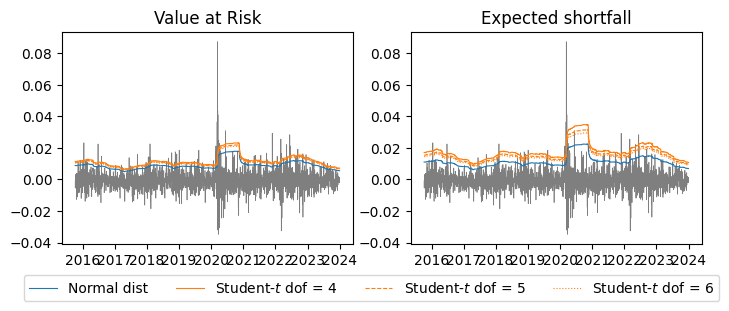

In [11]:
fig, axs = plt.subplots(1, 2, figsize = (8.2543, 8.2543 / 3))
axs[1].set_title('Expected shortfall')
axs[1].plot(PortRet(data = loss_df_sliced, weights = PORTFOLIO_WEIGHTS), lw = .5, c = 'black', alpha = .5)
axs[1].plot(ES_HS_normal, label = 'Normal dist', lw = .8)
axs[1].plot(ES_HS_student4, label = 'Student-$t$ dof = 4', c = 'C1', lw = .8)
axs[1].plot(ES_HS_student5, label = 'Student-$t$ dof = 5', c = 'C1', ls = 'dashed', lw = .8)
axs[1].plot(ES_HS_student6, label = 'Student-$t$ dof = 6', c = 'C1', ls = 'dotted', lw = .8)
# axs[1].plot(portfolio_sliced.index, ES_data_GARCH, label = 'GARCH', c = 'C2', ls = '-', lw = .8)
# axs[1].legend()

axs[0].set_title('Value at Risk')
axs[0].plot(PortRet(data = loss_df_sliced, weights = PORTFOLIO_WEIGHTS), lw = .5, c = 'black', alpha = .5)
axs[0].plot(VaR_HS_normal.VaR, label = 'Normal dist', lw = .8)
axs[0].plot(VaR_HS_student4.VaR, label = 'Student-$t$ dof = 4', c = 'C1', lw = .8)
axs[0].plot(VaR_HS_student5.VaR, label = 'Student-$t$ dof = 5', c = 'C1', ls = 'dashed', lw = .8)
axs[0].plot(VaR_HS_student6.VaR, label = 'Student-$t$ dof = 6', c = 'C1', ls = 'dotted', lw = .8)
# axs[0].legend(bbox_to_anchor=(0.5, -.3), loc='center', ncol=5)
lines_labels = [ax.get_legend_handles_labels() for ax in fig.axes][:1]
lines, labels = [sum(lol, []) for lol in zip(*lines_labels)][:2]
fig.legend(lines, labels, bbox_to_anchor=(0.5, -.05), loc='center', ncol=4)
plt.show()

In [12]:
def Historic_Simulation(data: pd.DataFrame, window_size: int, port_weights: np.array, alpha: float, **kwargs) -> float:
    """
    Calculate VaR and ES using historic simulation
    """

    # Calculate the volatility
    portfolio_returns = PortRet(data = data, weights = port_weights)
    
    df = pd.DataFrame([], index = data.index, columns = ['VaR'])
    VaR = portfolio_returns.rolling(window = window_size).quantile(alpha)
    ES  = [np.nan] * window_size
    for k in range(window_size, len(data)):
        _ = data.iloc[k - window_size: k]
        _ = _[_ >= VaR.iloc[k]]
        ES.append(np.mean(_))
    df['VaR'] = VaR
    df['ES'] = ES
    return df.dropna()

def filtered_HS(returns, weights, _alpha, window_size):
    Devol = pd.DataFrame([], index = returns.index)
    Vol = pd.DataFrame([], index = returns.index)
    for col in returns.columns:
        # Filter the volatility for each individual asset using the EWMA method
        x = returns[col]
        alpha = .05
        beta = 1 - alpha
        omega = 0
        vol = volatility(omega, alpha, beta, x)
        Vol[f'Vol {col}'] = vol
        Devol[f'Devol {col}'] = returns[col] / vol 
    # Calculate the portfolio volatility (not sure if correct)

    df = pd.DataFrame([], index = returns.index, columns = ['VaR'])

    # Define a rolling window VaR estimator
    ES  = [np.nan] * window_size
    VaR = [np.nan] * window_size
    for k in range(window_size, len(returns)):
        # Get the window over the devol object, and multiply with the predicted volatility
        D = Devol.iloc[k - window_size: k] * Vol.iloc[k].values

        # get the returns and calculate the VaR
        portfolio_returns = PortRet(data = D, weights = weights)
        VaR.append(portfolio_returns.rolling(window = window_size).quantile(_alpha).iloc[-1])
        
        _ = portfolio_returns[portfolio_returns >= VaR[k]]
        # The expected shortfall is the mean of the returns conditional on exceeding the var
        ES.append(np.mean(_))
    df['VaR'] = VaR
    df['ES'] = np.array(ES)
    return df.dropna()

In [13]:
VaR_ES_Historic_Simulation = Historic_Simulation(loss_df, window_size, PORTFOLIO_WEIGHTS, .95)

In [14]:
EWMA_HS = filtered_HS(loss_df, PORTFOLIO_WEIGHTS, .95, window_size)

In [15]:
GARCH = GARCH_portfolio_variance(loss_df_sliced, weights = PORTFOLIO_WEIGHTS)
VaR_GARCH = GARCH_VaR(GARCH, .95, stats.norm.ppf)
ES_GARCH = Var_Cov_ES(GARCH, .95, stats.norm)

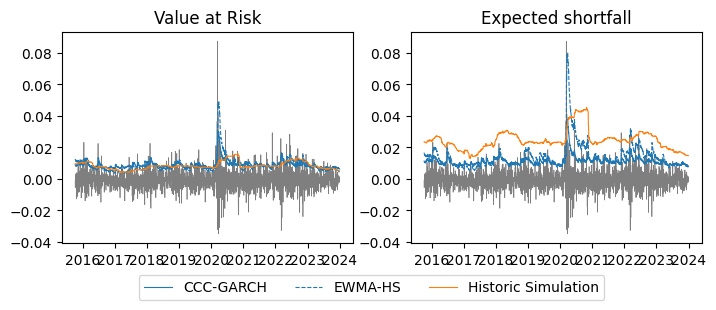

In [16]:
fig, axs = plt.subplots(1, 2, figsize = (8.2543, 8.2543 / 3))
axs[1].set_title('Expected shortfall')
axs[1].plot(PortRet(data = loss_df_sliced, weights = PORTFOLIO_WEIGHTS), lw = .5, c = 'black', alpha = .5)
axs[1].plot(loss_df_sliced.index, ES_GARCH, label = 'CCC-GARCH', lw = .8, c = 'C0')
axs[1].plot(EWMA_HS.ES, label = 'EWMA-HS', lw = .8, c = 'C0', ls = 'dashed')
axs[1].plot(VaR_ES_Historic_Simulation.ES, label = 'Historic Simulation', lw = .8, c = 'C1')
# axs[1].plot(portfolio_sliced.index, ES_data_GARCH, label = 'GARCH', c = 'C2', ls = '-', lw = .8)
# axs[1].legend()

axs[0].set_title('Value at Risk')
axs[0].plot(PortRet(data = loss_df_sliced, weights = PORTFOLIO_WEIGHTS), lw = .5, c = 'black', alpha = .5)
axs[0].plot(loss_df_sliced.index, VaR_GARCH, label = 'CCC-GARCH', c = 'C0', lw = .8)
axs[0].plot(EWMA_HS.VaR, label = 'EWMA-HS', lw = .8, c = 'C0', ls = 'dashed')
axs[0].plot(VaR_ES_Historic_Simulation.VaR, label = 'Historic Simulation', lw = .8, c = 'C1')
# axs[0].legend(bbox_to_anchor=(0.5, -.3), loc='center', ncol=5)
lines_labels = [ax.get_legend_handles_labels() for ax in fig.axes][:1]
lines, labels = [sum(lol, []) for lol in zip(*lines_labels)][:2]
fig.legend(lines, labels, bbox_to_anchor=(0.5, -.05), loc='center', ncol=4)
plt.show()